
## Part 1: Experimental Design & Data Preparation

### 1.1 Modeling objective, target and feature set

**Modeling objective:** Predict whether a bank client will subscribe to a term deposit (`y` = yes/no) after a marketing call. This is a **binary classification** task.

**Business goal:** Help the bank decide which clients to call. Calling a client who will not subscribe wastes time, but missing a client who would subscribe loses revenue. The "yes" class (11.5% of clients) is the one that matters.

**Target variable:** `y` (no = 0, yes = 1).

**Feature set (decided in Milestone 3):**
- `duration` is **excluded**. It is only known after the call ends, so using it would be data leakage.
- `default` is **excluded**. It has almost no relation to the target (11.84% vs 11.52%).
- All other 14 columns are kept as input features, and "unknown" is kept as its own category.

**Evaluation criteria:** Because only 11.5% of clients are "yes", accuracy is misleading (always predicting "no" gives 88.5%). The main metrics are **PR-AUC** and **ROC-AUC** (they do not depend on a threshold), plus **recall, precision and F1** of the "yes" class.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("bank.csv", sep=";")

y = df["y"].map({"no": 0, "yes": 1})
X = df.drop(columns=["y", "duration", "default"])

numeric_features = ["age", "balance", "day", "campaign", "pdays", "previous"]
categorical_features = ["job", "marital", "education", "housing", "loan",
                        "contact", "month", "poutcome"]

print("X shape:", X.shape)
print("Target counts:", y.value_counts().to_dict())
print("Target rate: {:.2f}%".format(y.mean() * 100))
print("\nNumeric    :", numeric_features)
print("Categorical:", categorical_features)
print("All features covered:", sorted(numeric_features + categorical_features) == sorted(X.columns.tolist()))

X shape: (4521, 14)
Target counts: {0: 4000, 1: 521}
Target rate: 11.52%

Numeric    : ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'housing', 'loan', 'contact', 'month', 'poutcome']
All features covered: True


**Findings:**
- X has 4,521 rows and 14 features: 6 numeric and 8 categorical. `duration` and `default` have been removed from the original 16 inputs.
- The target has 4,000 "no" (0) and 521 "yes" (1), a "yes" rate of 11.52%. This matches Milestone 3.
- The check returned `True`, so every remaining column is assigned to exactly one group.
- Because the "yes" class is the minority, the evaluation focuses on PR-AUC, ROC-AUC, recall, precision and F1, not accuracy.

### 1.2 Validation strategy

**Approach:**
- **Test set (20%):** split off first with `stratify=y`. It is not used for preprocessing, tuning, augmentation or model selection. It is used only in Part 4 to report the final results, and no decision was changed after looking at it.
- **Training set (80%):** used for model comparison and hyperparameter tuning with **stratified 5 fold cross-validation**. Each fold in turn acts as the validation set, so every training row is used for validation once, and each fold keeps the same share of "yes".
- Why cross-validation instead of one validation split: only 521 clients are "yes", so about 417 are in the training set. A single validation split would hold only about 80 "yes" cases, which gives noisy scores. Five folds give five estimates and show how stable the model is.

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Train:", X_train.shape, "| yes rate: {:.2f}%".format(y_train.mean() * 100))
print("Test :", X_test.shape, "| yes rate: {:.2f}%".format(y_test.mean() * 100))

print("\nFold sizes inside the training set:")
for i, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    print("Fold {}: train {} | validation {} | validation yes rate {:.2f}%".format(
        i, len(tr_idx), len(val_idx), y_train.iloc[val_idx].mean() * 100))

Train: (3616, 14) | yes rate: 11.53%
Test : (905, 14) | yes rate: 11.49%

Fold sizes inside the training set:
Fold 1: train 2892 | validation 724 | validation yes rate 11.60%
Fold 2: train 2893 | validation 723 | validation yes rate 11.48%
Fold 3: train 2893 | validation 723 | validation yes rate 11.48%
Fold 4: train 2893 | validation 723 | validation yes rate 11.48%
Fold 5: train 2893 | validation 723 | validation yes rate 11.62%


**Findings:**
- The training set has 3,616 rows (11.53% "yes") and the test set has 905 rows (11.49% "yes"). Both are close to the overall 11.52%, so stratification worked.
- Each cross-validation fold trains on about 2,893 rows and validates on about 723 rows. The validation "yes" rate is between 11.48% and 11.62% in every fold, so all folds have the same class balance and the fold scores can be compared fairly.
- The test set is now set aside. It is not used again until the final evaluation.

### 1.3 Preprocessing pipeline (leakage-safe)

**Decisions and justification:**
- **Missing values:** there are no `NaN` values. Hidden missing values (`"unknown"` in poutcome, contact, education, job) are kept as their own category, because "unknown" carries information (for example `contact = unknown` subscribes at only 4.61%). Imputing 29% to 82% of a column would add false information.
- **Feature engineering:** `previously_contacted` flag (1 if `pdays` is not -1) and the placeholder -1 in `pdays` is replaced by 0.
- **Outliers:** `balance` and `campaign` are capped at the 99th percentile. No rows are removed, because outliers carry signal (Milestone 3).
- **Transformation:** `log1p` on `balance` (signed, because balance can be negative) and on `campaign`, to reduce skew.
- **Scaling:** `StandardScaler` on the numeric columns, which helps logistic regression and KNN type models.
- **Encoding:** one-hot encoding of the 8 categorical columns. `handle_unknown="ignore"` means a category that only appears in a validation or test fold does not crash the pipeline.

**Why this prevents data leakage:** the 99th percentile caps, the scaler's mean and standard deviation, and the one-hot categories are all *learned* in `fit`. In a `Pipeline`, `fit` is only called on training data, and the validation or test data only goes through `transform`.

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


class AddFlag(BaseEstimator, TransformerMixin):
    """previously_contacted flag, and replace the -1 placeholder in pdays by 0."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["previously_contacted"] = (X["pdays"] != -1).astype(int)
        X["pdays"] = X["pdays"].replace(-1, 0)
        return X


class Capper(BaseEstimator, TransformerMixin):
    """Cap balance and campaign at the 99th percentile learned in fit."""
    def __init__(self, q=0.99):
        self.q = q
    def fit(self, X, y=None):
        self.limits_ = {c: X[c].quantile(self.q) for c in ["balance", "campaign"]}
        return self
    def transform(self, X):
        X = X.copy()
        for c, limit in self.limits_.items():
            X[c] = X[c].clip(upper=limit)
        return X


class LogTransform(BaseEstimator, TransformerMixin):
    """Signed log1p for balance, log1p for campaign."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["balance"] = np.sign(X["balance"]) * np.log1p(X["balance"].abs())
        X["campaign"] = np.log1p(X["campaign"])
        return X


num_cols = numeric_features + ["previously_contacted"]

encode_scale = ColumnTransformer(
    [("num", StandardScaler(), num_cols),
     ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
    sparse_threshold=0)

preprocessor = Pipeline([
    ("flag", AddFlag()),
    ("cap", Capper()),
    ("log", LogTransform()),
    ("encode_scale", encode_scale),
])

# Fit on the training set only, then apply to the test set
Xtr = preprocessor.fit_transform(X_train)
Xte = preprocessor.transform(X_test)

print("Processed train shape:", Xtr.shape)
print("Processed test shape :", Xte.shape)
print("Caps learned from train:", {k: round(float(v), 1) for k, v in preprocessor.named_steps["cap"].limits_.items()})
print("Any NaN left:", bool(np.isnan(Xtr).any() or np.isnan(Xte).any()))
print("Train numeric mean:", Xtr[:, :7].mean(axis=0).round(2))
print("Train numeric std :", Xtr[:, :7].std(axis=0).round(2))
print("Test numeric mean :", Xte[:, :7].mean(axis=0).round(2))

Processed train shape: (3616, 49)
Processed test shape : (905, 49)
Caps learned from train: {'balance': 13704.7, 'campaign': 16.8}
Any NaN left: False
Train numeric mean: [-0.  0.  0. -0.  0.  0. -0.]
Train numeric std : [1. 1. 1. 1. 1. 1. 1.]
Test numeric mean : [ 0.06  0.04 -0.08  0.01 -0.02 -0.01 -0.06]


**Findings:**
- The pipeline turns the 14 raw features into **49 model-ready columns**: 7 numeric columns (the 6 original numeric columns plus `previously_contacted`) and 42 one-hot columns. Train and test have the same width, so the same model can be applied to both.
- No `NaN` values are left.
- The caps were learned from the training set only: `balance` at 13,704.7 and `campaign` at 16.8. The test set was only transformed with them.
- Training numeric columns have mean 0 and standard deviation 1. The test columns are close to, but not exactly, 0 and 1 (for example age 0.06). This is expected, because the scaler used training statistics only and the test set is not forced to look like the training set.

### 1.4 Data leakage: audit and sanity check

**Possible leakage sources and how each is handled:**

| Source | Risk | How it is prevented |
|---|---|---|
| `duration` | Only known after the call, so it would not exist at prediction time | Removed from the features |
| Test set | Used for tuning or preprocessing would make the final score optimistic | Split off first, not touched until the final evaluation |
| Capping thresholds, scaler, one-hot categories | Learned from all rows, they would carry information from validation or test rows | Inside a `Pipeline`, re-fitted on the training part of every fold |
| Augmentation (Part 2) | Synthetic rows made before the split would copy information into validation rows | Applied only to the training part of each fold, never to validation or test |
| `poutcome`, `pdays`, `previous` | They describe the *previous* campaign, so they are known before the call | Kept (no leakage) |

In [5]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.base import clone

print("Balance cap learned inside each fold:")
for i, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    p = clone(preprocessor).fit(X_train.iloc[tr_idx])
    print("Fold {}: {:.1f}".format(i, float(p.named_steps["cap"].limits_["balance"])))
print("Whole training set: {:.1f}".format(float(preprocessor.named_steps["cap"].limits_["balance"])))

scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}
reference_models = {
    "Majority-class baseline": DummyClassifier(strategy="prior"),
    "Logistic regression (default)": LogisticRegression(max_iter=1000),
}

print("\n5-fold cross-validation on the training set:")
for name, model in reference_models.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    print("{:30s} ROC-AUC {:.3f} +/- {:.3f} | PR-AUC {:.3f} +/- {:.3f}".format(
        name, r["test_roc_auc"].mean(), r["test_roc_auc"].std(),
        r["test_pr_auc"].mean(), r["test_pr_auc"].std()))

Balance cap learned inside each fold:
Fold 1: 14061.2
Fold 2: 13725.6
Fold 3: 13725.6
Fold 4: 14082.4
Fold 5: 13354.2
Whole training set: 13704.7

5-fold cross-validation on the training set:
Majority-class baseline        ROC-AUC 0.500 +/- 0.000 | PR-AUC 0.115 +/- 0.001
Logistic regression (default)  ROC-AUC 0.724 +/- 0.026 | PR-AUC 0.357 +/- 0.045


**Findings:**
- **Leakage check:** the `balance` cap is different in every fold (13,354 to 14,082) and differs again from the whole training set cap (13,704.7). This shows the preprocessing is relearned from each fold's training rows, and no information from the validation rows is used.
- **Majority-class baseline:** ROC-AUC 0.500 and PR-AUC 0.115. The PR-AUC of a model with no skill equals the "yes" rate (about 11.5%), so **0.115 is the floor** that any useful model must beat.
- **Default logistic regression:** ROC-AUC 0.724 +/- 0.026 and PR-AUC 0.357 +/- 0.045. This is roughly 3 times the baseline PR-AUC, so the features carry real signal even without `duration`.
- The standard deviation across folds is small for ROC-AUC (0.026) and larger for PR-AUC (0.045). The PR-AUC depends on only about 83 "yes" cases per validation fold, so it is the noisier metric and later comparisons must be read with that spread in mind.
- **Conclusion for Part 1:** the objective, target, features, evaluation metrics, validation strategy and leakage safe pipeline are defined. Part 1 is complete.

## Part 2: Data Generation / Augmentation

### 2.1 Diagnosing the class imbalance

The "yes" class is 11.5% of the data (7.7 : 1). Augmentation is not automatically needed: it is only justified if the imbalance hurts the model. Two things are checked:
1. **How few minority samples are there?** (sparse minority samples)
2. **Does a default model fail on the minority class?** A model at the default 0.5 threshold that finds few "yes" clients is a sign of the imbalance problem.

In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

print("Minority (yes) rows in training set:", int(y_train.sum()), "of", len(y_train))
for i, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    print("Fold {}: yes in fold-train {} | yes in fold-validation {}".format(
        i, int(y_train.iloc[tr_idx].sum()), int(y_train.iloc[val_idx].sum())))

pipe = Pipeline([("prep", clone(preprocessor)), ("model", LogisticRegression(max_iter=1000))])
pred = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict")

print("\nDefault logistic regression, threshold 0.5 (out-of-fold predictions):")
print(confusion_matrix(y_train, pred))
print("Precision {:.3f} | Recall {:.3f} | F1 {:.3f}".format(
    precision_score(y_train, pred), recall_score(y_train, pred), f1_score(y_train, pred)))

Minority (yes) rows in training set: 417 of 3616
Fold 1: yes in fold-train 333 | yes in fold-validation 84
Fold 2: yes in fold-train 334 | yes in fold-validation 83
Fold 3: yes in fold-train 334 | yes in fold-validation 83
Fold 4: yes in fold-train 334 | yes in fold-validation 83
Fold 5: yes in fold-train 333 | yes in fold-validation 84

Default logistic regression, threshold 0.5 (out-of-fold predictions):
[[3158   41]
 [ 354   63]]
Precision 0.606 | Recall 0.151 | F1 0.242


**Findings:**
- The training set has only **417 "yes" rows**, and each fold trains on about 333 of them and validates on 83 to 84. This is a sparse minority class: a model has few examples to learn from, and a validation score from 83 cases is noisy.
- At the default 0.5 threshold the logistic regression finds only **63 of 417 subscribers (recall 0.151)**. It misses 354 of them. Its precision is 0.606, so when it says "yes" it is usually right, but it says "yes" very rarely (104 times out of 3,616).
- This is the typical imbalance problem. The model is pushed towards "no" because "no" is 88.5% of the training data, and a client needs a predicted probability above 0.5 to be flagged, which few subscribers reach.
- **Conclusion:** the imbalance does hurt the minority class recall, so a strategy for it is justified. Two candidates are compared in 2.2: (1) class weights, which make errors on "yes" count more and add no synthetic data, and (2) SMOTE, which creates synthetic "yes" rows. Both are applied to the training part of each fold only.

### 2.2 Comparing: no strategy vs class weights vs SMOTE

**Methods:**
- **No strategy (before):** the default logistic regression from Part 1.
- **Class weights:** `class_weight="balanced"` gives each "yes" row a weight of about 7.7, so a missed subscriber costs as much as 7.7 missed non-subscribers. No data is created.
- **SMOTE:** creates synthetic "yes" rows by interpolating between a real "yes" row and one of its nearest "yes" neighbours, until both classes are the same size.

**How leakage is prevented:** SMOTE is a step in an `imblearn` Pipeline. In each cross-validation fold it is applied to the training part only, and it is skipped when the validation part is scored. So the validation fold never contains synthetic rows or copies of them, and the test set is not used at all.

**Metrics:** ROC-AUC and PR-AUC do not depend on a threshold and show whether the model ranks clients better. Precision, recall and F1 of the "yes" class are measured at the 0.5 threshold and show how the decisions change.

In [7]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


def make_pipe(model, use_smote=False):
    """Preprocessing steps (flattened) -> optional SMOTE -> model."""
    steps = [(name, clone(step)) for name, step in preprocessor.steps]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=42)))
    steps.append(("model", model))
    return ImbPipeline(steps)


strategies = {
    "No strategy (before)": make_pipe(LogisticRegression(max_iter=1000)),
    "Class weights": make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "SMOTE": make_pipe(LogisticRegression(max_iter=1000), use_smote=True),
}

scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "precision": "precision", "recall": "recall", "f1": "f1"}

rows = []
for name, pipe in strategies.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"strategy": name}
    for m in scoring:
        row[m] = "{:.3f} +/- {:.3f}".format(r["test_" + m].mean(), r["test_" + m].std())
    rows.append(row)

pd.DataFrame(rows).set_index("strategy")

,roc_auc,pr_auc,precision,recall,f1
strategy,,,,,
No strategy (before),0.724 +/- 0.026,0.357 +/- 0.045,0.608 +/- 0.144,0.151 +/- 0.046,0.240 +/- 0.069
Class weights,0.724 +/- 0.025,0.354 +/- 0.041,0.220 +/- 0.007,0.576 +/- 0.051,0.318 +/- 0.014
SMOTE,0.720 +/- 0.028,0.345 +/- 0.046,0.215 +/- 0.012,0.573 +/- 0.037,0.312 +/- 0.015


**Findings:**

| Strategy | ROC-AUC | PR-AUC | Precision | Recall | F1 |
|---|---|---|---|---|---|
| No strategy (before) | 0.724 | 0.357 | 0.608 | 0.151 | 0.240 |
| Class weights | 0.724 | 0.354 | 0.220 | 0.576 | 0.318 |
| SMOTE | 0.720 | 0.345 | 0.215 | 0.573 | 0.312 |

- **Ranking quality did not improve.** ROC-AUC (0.724, 0.724, 0.720) and PR-AUC (0.357, 0.354, 0.345) are practically the same for all three. The differences are far smaller than the fold-to-fold standard deviation (0.025 to 0.046), so they are noise.
- **Decisions at the 0.5 threshold changed a lot.** Recall rose from 0.151 to about 0.57, so the model now finds about 4 times as many subscribers. Precision fell from 0.608 to about 0.22, so only about 1 in 5 flagged clients subscribes. F1 rose from 0.240 to about 0.31.
- Because the threshold-free scores did not move, the gain in recall and F1 looks like a **shift of the decision threshold**, not a better model. Class weights and SMOTE both make the model more willing to say "yes". Whether this is a real improvement is tested in 2.3.
- **SMOTE did not beat class weights.** It is slightly lower on every metric except recall, which is the same within noise. It also needs about 2,225 synthetic rows in each fold (the fold's training part has about 2,559 "no" and 334 "yes" rows), while class weights create no data.
- The precision of the baseline has a large spread (+/- 0.144) because it flags very few clients per fold (about 20), so a few right or wrong calls change it a lot.

### 2.3 Did augmentation really help?

The table in 2.2 mixes two effects: a better model, and a different decision threshold. Two checks separate them.

1. **Paired comparison.** All strategies use the same folds, so the PR-AUC of each strategy can be compared with the baseline fold by fold. If an approach is truly better, it should win in most folds.
2. **Threshold tuning.** The baseline is unfair at 0.5 because its probabilities are low. If the baseline's threshold is tuned (on out of fold probabilities) to maximize F1, does resampling still give a better F1? If not, class weights and SMOTE only did what a lower threshold does.

In [8]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Out-of-fold probabilities for each strategy (same folds for all)
oof = {}
for name, pipe in strategies.items():
    oof[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# 1) Paired comparison of PR-AUC, fold by fold
base = "No strategy (before)"
fold_ap = {name: [] for name in strategies}
for tr_idx, val_idx in cv.split(X_train, y_train):
    for name in strategies:
        fold_ap[name].append(average_precision_score(y_train.iloc[val_idx], oof[name][val_idx]))

print("PR-AUC difference vs 'No strategy', fold by fold:")
for name in strategies:
    if name == base:
        continue
    diff = np.array(fold_ap[name]) - np.array(fold_ap[base])
    print("{:15s} mean diff {:+.3f} | per fold {} | better in {}/5 folds".format(
        name, diff.mean(), np.round(diff, 3), int((diff > 0).sum())))

# 2) Best F1 when the threshold is tuned
print("\nBest possible F1 for each strategy when the threshold is tuned:")
for name in strategies:
    p, r, t = precision_recall_curve(y_train, oof[name])
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    k = f1.argmax()
    print("{:22s} F1 {:.3f} at threshold {:.2f} (precision {:.3f}, recall {:.3f})".format(
        name, f1[k], t[k], p[k], r[k]))

PR-AUC difference vs 'No strategy', fold by fold:
Class weights   mean diff -0.003 | per fold [ 0.001 -0.008 -0.022  0.008  0.005] | better in 3/5 folds
SMOTE           mean diff -0.012 | per fold [-0.014 -0.012 -0.023 -0.011  0.002] | better in 1/5 folds

Best possible F1 for each strategy when the threshold is tuned:
No strategy (before)   F1 0.392 at threshold 0.25 (precision 0.510, recall 0.319)
Class weights          F1 0.377 at threshold 0.72 (precision 0.478, recall 0.312)
SMOTE                  F1 0.368 at threshold 0.67 (precision 0.392, recall 0.348)


**Findings:**
- **Paired comparison:** compared with the baseline, class weights change the PR-AUC by −0.003 on average and win in 3 of 5 folds. SMOTE changes it by −0.012 and wins in only 1 of 5 folds. Neither approach improves the ranking of clients, and SMOTE is slightly worse in four folds out of five.
- **Threshold tuning removes the apparent gain.** When each strategy gets its best possible threshold, the tuned baseline reaches F1 0.392, class weights 0.377 and SMOTE 0.368. The baseline is the best of the three. The F1 jump from 0.240 to about 0.31 in 2.2 came from the 0.5 threshold being a bad choice for the baseline, not from a better model.
- The three strategies end up at similar precision and recall trade offs. Class weights and SMOTE just move the model to a different point on the same precision-recall curve, and the baseline can reach that point by lowering its threshold to about 0.25.
- **Decision (to be checked in 2.4):** the imbalance matters for *decisions* (the 0.5 threshold), but not for the *ranking quality*. The cheaper and safer fix is to choose the decision threshold from cross validated probabilities. SMOTE is not kept in the final pipeline, because it adds synthetic data and gives no gain. Class weights stay available as a hyperparameter in Part 3.
- The tuned thresholds were chosen on the same out of fold probabilities that are scored, so these F1 values are slightly optimistic. Since this affects all three strategies equally, the comparison between them is still fair. The final threshold will be checked on the untouched test set in Part 4.

### 2.4 Risks of synthetic data and re-weighting

Three risks have to be checked, not just mentioned:

1. **Distribution distortion.** Balancing the classes makes the model believe "yes" is as common as "no". Its predicted probabilities then no longer match real frequencies (about 11.5% of clients subscribe). A bank that uses the probability to decide how many clients to call would be misled. This is measured with the mean predicted probability and the Brier score (lower is better).
2. **Overfitting to synthetic data.** SMOTE points are copies in between real points, so a flexible model can memorize them and score well on training data but worse on validation data. This is measured with the gap between the training and validation PR-AUC.
3. **Bias amplification.** If the minority class is mainly made of one type of client, reweighting or SMOTE can make the model favour that type even more. As a simple check, recall is compared across age groups.

In [9]:
from sklearn.metrics import brier_score_loss, recall_score

# 1) Distribution distortion
rows = []
for name in strategies:
    p = oof[name]
    rows.append({"strategy": name,
                 "mean predicted P(yes)": round(p.mean(), 3),
                 "actual yes rate": round(y_train.mean(), 3),
                 "Brier score": round(brier_score_loss(y_train, p), 3),
                 "flagged at 0.5 (%)": round((p >= 0.5).mean() * 100, 1)})
print(pd.DataFrame(rows).set_index("strategy").to_string())

# 2) Bias amplification: recall by age group at threshold 0.5
age_group = pd.cut(X_train["age"], [0, 30, 60, 100], labels=["<=30", "31-60", ">60"])
print("\nRecall at threshold 0.5 by age group (number of yes in brackets):")
out = {}
for name in strategies:
    pred = (oof[name] >= 0.5).astype(int)
    out[name] = {g: "{:.2f} ({})".format(
        recall_score(y_train[age_group == g], pred[(age_group == g).values]),
        int(y_train[age_group == g].sum())) for g in age_group.cat.categories}
print(pd.DataFrame(out).to_string())

# 3) Overfitting check: training vs validation PR-AUC
print("\nTrain vs validation PR-AUC:")
for name, pipe in strategies.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring={"pr_auc": "average_precision"}, return_train_score=True)
    print("{:22s} train {:.3f} | validation {:.3f} | gap {:.3f}".format(
        name, r["train_pr_auc"].mean(), r["test_pr_auc"].mean(),
        r["train_pr_auc"].mean() - r["test_pr_auc"].mean()))

                      mean predicted P(yes)  actual yes rate  Brier score  flagged at 0.5 (%)
strategy                                                                                     
No strategy (before)                  0.116            0.115        0.089                 2.9
Class weights                         0.422            0.115        0.195                30.1
SMOTE                                 0.409            0.115        0.193                30.8

Recall at threshold 0.5 by age group (number of yes in brackets):
      No strategy (before) Class weights       SMOTE
<=30             0.17 (75)     0.55 (75)   0.57 (75)
31-60           0.13 (306)    0.55 (306)  0.54 (306)
>60              0.31 (36)     0.89 (36)   0.86 (36)

Train vs validation PR-AUC:
No strategy (before)   train 0.393 | validation 0.357 | gap 0.036
Class weights          train 0.381 | validation 0.354 | gap 0.027
SMOTE                  train 0.377 | validation 0.345 | gap 0.031


**Findings:**
- **Distribution distortion is large:** The real "yes" rate is 11.5% and the baseline predicts 11.6% on average, so its probabilities are well calibrated. Class weights (0.422) and SMOTE (0.409) predict about 41% to 42%, almost 4 times too high. Their Brier scores (0.195 and 0.193) are more than double the baseline's (0.089). Both flag about 30% of all clients at 0.5, against 2.9% for the baseline. The probabilities from these models cannot be read as "chance this client subscribes" without recalibration.
- **No relative amplification across age groups:** Recall rises by a similar factor (about 3 to 4 times) in all three groups. But clients over 60 are caught almost always after reweighting (recall 0.89 and 0.86), the highest of the three groups, which means the reweighted models flag most of them. This is examined further in 4.2. The groups are small (36 "yes" clients over 60), so this is a coarse check, not a fairness audit.
- **Overfitting to synthetic data is not found either:** The training validation PR-AUC gap is 0.036 for the baseline, 0.027 for class weights and 0.031 for SMOTE. A logistic regression is too simple to memorize synthetic points. This risk would be higher for a flexible model such as a random forest or boosting, which is one more reason not to use SMOTE there.

### Conclusion of Part 2
- **Was augmentation necessary?** Only partly. The imbalance (7.7 : 1, 417 "yes" training rows) makes the default 0.5 threshold useless (recall 0.15), but it does not reduce the model's ability to rank clients.
- **Did it improve generalization?** No. Across folds, SMOTE lowered PR-AUC (−0.012, better in 1 of 5 folds) and class weights were equal within noise (−0.003). Once the baseline's threshold is tuned, it has the best F1 (0.392 vs 0.377 and 0.368). The same holds for the final random forest (see 4.6).
- **Costs of augmenting:** inflated probabilities (Brier score more than doubles), extra complexity, and a leakage risk if it were applied before the split.
- **Decision:** SMOTE is not used in the final model. The imbalance is handled by choosing the decision threshold from cross-validated probabilities, and `class_weight` is kept as a tunable option in Part 3. Metrics that do not depend on the threshold (PR-AUC, ROC-AUC) are used to compare models.

## Part 3: Final Model Development & Optimization

### 3.1 Candidate models

Three models are compared. They cover a range from simple to flexible:

| Model | Why it is a candidate | Main assumptions |
|---|---|---|
| **Logistic regression** | Simple, fast, interpretable coefficients; a strong baseline for tabular data | Each feature has a linear effect on the log-odds of "yes"; no interactions unless added by hand; features are not strongly collinear (one-hot columns are mildly collinear, which the L2 penalty handles) |
| **Random forest** | Captures non-linear effects and interactions without manual features; robust to outliers and to the skewed numeric columns | Rows are independent; trees can overfit if they are too deep, which is controlled with `min_samples_leaf` |
| **Gradient boosting** (`HistGradientBoostingClassifier`) | Usually the best accuracy on tabular data; handles non-linearity and interactions | Rows are independent; sensitive to the learning rate and number of trees, so early stopping or a small learning rate is needed |

**Tuning method:** `GridSearchCV` on the training set with the same stratified 5-fold split, scored with **PR-AUC** (`average_precision`). PR-AUC is chosen because it focuses on how well the "yes" clients are ranked and does not depend on a threshold. The test set is not touched. Each search re-fits the whole preprocessing pipeline inside every fold, so there is no leakage.

In [10]:
from sklearn.model_selection import GridSearchCV

tuned = {}   # keeps every tuned model for the comparison later

lr_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", LogisticRegression(max_iter=2000))])

lr_grid = {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
           "model__class_weight": [None, "balanced"]}

lr_search = GridSearchCV(lr_pipe, lr_grid, scoring="average_precision",
                         cv=cv, return_train_score=True)
lr_search.fit(X_train, y_train)
tuned["Logistic regression"] = lr_search

res = pd.DataFrame(lr_search.cv_results_)
res = res[["param_model__C", "param_model__class_weight",
           "mean_train_score", "mean_test_score", "std_test_score"]]
res.columns = ["C", "class_weight", "train PR-AUC", "val PR-AUC", "val std"]
res["class_weight"] = res["class_weight"].astype(str)

print(res.sort_values("val PR-AUC", ascending=False).head(6).round(3).to_string(index=False))
print("\nBest params:", lr_search.best_params_)
print("Best CV PR-AUC: {:.3f}".format(lr_search.best_score_))

   C class_weight  train PR-AUC  val PR-AUC  val std
 0.3         None         0.390       0.358    0.043
   1         None         0.393       0.357    0.045
   3         None         0.393       0.356    0.044
  10         None         0.393       0.355    0.045
 0.3     balanced         0.380       0.354    0.039
   1     balanced         0.381       0.354    0.041

Best params: {'model__C': 0.3, 'model__class_weight': None}
Best CV PR-AUC: 0.358


**Findings (logistic regression):**
- The best setting is `C = 0.3` with no class weights, with a validation PR-AUC of **0.358 +/- 0.043**.
- The top four settings are within 0.003 of each other, which is far below the fold to fold spread (0.043). The model is not sensitive to `C` in this range, so there is no strong tuning gain to find.
- Balanced class weights are 0.004 lower in validation PR-AUC (0.354). This agrees with Part 2: reweighting changes the decision threshold but not the ranking.
- The training PR-AUC (0.390) is only 0.032 above validation, so the model is not overfitting. It is more likely to **underfit** (high bias): it can only draw straight line effects, and its score has hardly moved from the default model (0.357).

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))])

rf_grid = {"model__max_depth": [6, 12, None],
           "model__min_samples_leaf": [3, 10, 20],
           "model__max_features": ["sqrt", 0.3]}

rf_search = GridSearchCV(rf_pipe, rf_grid, scoring="average_precision",
                         cv=cv, return_train_score=True)
rf_search.fit(X_train, y_train)
tuned["Random forest"] = rf_search

res = pd.DataFrame(rf_search.cv_results_)
res = res[["param_model__max_depth", "param_model__min_samples_leaf", "param_model__max_features",
           "mean_train_score", "mean_test_score", "std_test_score"]]
res.columns = ["max_depth", "min_samples_leaf", "max_features", "train PR-AUC", "val PR-AUC", "val std"]
res["max_depth"] = res["max_depth"].fillna("None").astype(str)
res["max_features"] = res["max_features"].astype(str)

print(res.sort_values("val PR-AUC", ascending=False).head(6).round(3).to_string(index=False))
print("\nBest params:", rf_search.best_params_)
print("Best CV PR-AUC: {:.3f}".format(rf_search.best_score_))

max_depth min_samples_leaf max_features  train PR-AUC  val PR-AUC  val std
       12                3          0.3         0.795       0.381    0.048
     None                3          0.3         0.920       0.379    0.054
     None                3         sqrt         0.863       0.378    0.047
       12               10          0.3         0.594       0.376    0.050
       12                3         sqrt         0.751       0.376    0.044
        6                3          0.3         0.557       0.375    0.049

Best params: {'model__max_depth': 12, 'model__max_features': 0.3, 'model__min_samples_leaf': 3}
Best CV PR-AUC: 0.381


**Findings (random forest):**
- The best forest (`max_depth = 12`, `min_samples_leaf = 3`, `max_features = 0.3`) reaches a validation PR-AUC of **0.381 +/- 0.048**. This is 0.023 above the tuned logistic regression (0.358).
- The forest **overfits strongly**: its training PR-AUC is 0.795 against 0.381 on validation. Even the least flexible settings in the table (`max_depth = 6`, training 0.557) show a gap of about 0.18. A gap this large is high variance. The best settings are the ones that still allow fairly deep trees, with only a few clients per leaf, which suggests there are small, specific patterns that deeper trees can find.
- The top six settings are within 0.006 of each other, which is smaller than the fold spread (0.048). The choice among them is not meaningful, so the more regularized `max_depth = 12, min_samples_leaf = 10` (0.376, training 0.594) is nearly as good with a smaller gap.
- The best value of `min_samples_leaf` (3) is the lowest value in the grid, so the true optimum may be lower. The difference is expected to be small.
- The improvement over the logistic regression (+0.023) is about half of one fold standard deviation. It points towards non-linear effects but is not yet clear evidence. Part 4 checks this with repeated cross-validation.

In [12]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", HistGradientBoostingClassifier(random_state=42))])

gb_grid = {"model__learning_rate": [0.03, 0.1],
           "model__max_iter": [100, 250],
           "model__max_leaf_nodes": [4, 8, 16],
           "model__min_samples_leaf": [20, 50]}

gb_search = GridSearchCV(gb_pipe, gb_grid, scoring="average_precision",
                         cv=cv, return_train_score=True, n_jobs=-1)
gb_search.fit(X_train, y_train)
tuned["Gradient boosting"] = gb_search

res = pd.DataFrame(gb_search.cv_results_)
res = res[["param_model__learning_rate", "param_model__max_iter", "param_model__max_leaf_nodes",
           "param_model__min_samples_leaf", "mean_train_score", "mean_test_score", "std_test_score"]]
res.columns = ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf",
               "train PR-AUC", "val PR-AUC", "val std"]

print(res.sort_values("val PR-AUC", ascending=False).head(6).round(3).to_string(index=False))
print("\nBest params:", gb_search.best_params_)
print("Best CV PR-AUC: {:.3f}".format(gb_search.best_score_))

learning_rate max_iter max_leaf_nodes min_samples_leaf  train PR-AUC  val PR-AUC  val std
         0.03      250              4               20         0.493       0.372    0.060
          0.1      100              4               20         0.518       0.370    0.058
          0.1      250              4               20         0.625       0.369    0.055
         0.03      100             16               20         0.628       0.369    0.061
         0.03      250              8               20         0.612       0.365    0.056
          0.1      250              4               50         0.567       0.363    0.046

Best params: {'model__learning_rate': 0.03, 'model__max_iter': 250, 'model__max_leaf_nodes': 4, 'model__min_samples_leaf': 20}
Best CV PR-AUC: 0.372


**Findings (gradient boosting):**
- The best model (`learning_rate = 0.03`, 250 trees, `max_leaf_nodes = 4`, `min_samples_leaf = 20`) reaches a validation PR-AUC of **0.372 +/- 0.060**.
- The best settings all use **small trees** (4 leaves) or a small learning rate. The training PR-AUC for the best model is 0.493, so the gap to validation (0.121) is much smaller than for the random forest (0.414). Boosting with small trees is the more regularized of the two tree models here.
- The top five settings are within 0.01 of each other, again less than the fold spread (0.06), so there is no clearly best setting.
- Its fold spread (0.060) is the largest of the three models, so its score changes more from one fold to another.

### 3.2 Model comparison
All three tuned models are scored on the same 5 folds, so their results are directly comparable. The comparison looks at four things: the average validation score, the spread across folds, the training validation gap (overfitting), and the **paired** difference to the logistic regression.

In [13]:
rows, fold = [], {}
for name, search in tuned.items():
    r = cross_validate(search.best_estimator_, X_train, y_train, cv=cv,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
                       return_train_score=True)
    fold[name] = r["test_pr_auc"]
    rows.append({"model": name,
                 "val ROC-AUC": "{:.3f} +/- {:.3f}".format(r["test_roc_auc"].mean(), r["test_roc_auc"].std()),
                 "val PR-AUC": "{:.3f} +/- {:.3f}".format(r["test_pr_auc"].mean(), r["test_pr_auc"].std()),
                 "train PR-AUC": round(r["train_pr_auc"].mean(), 3),
                 "gap": round(r["train_pr_auc"].mean() - r["test_pr_auc"].mean(), 3)})

print(pd.DataFrame(rows).set_index("model").to_string())

print("\nPR-AUC per fold:")
print(pd.DataFrame(fold).round(3).to_string())

ref = "Logistic regression"
print("\nPaired difference vs logistic regression (PR-AUC):")
for name in fold:
    if name != ref:
        d = fold[name] - fold[ref]
        print("{:20s} mean {:+.3f} | better in {}/5 folds".format(name, d.mean(), int((d > 0).sum())))

                         val ROC-AUC       val PR-AUC  train PR-AUC    gap
model                                                                     
Logistic regression  0.726 +/- 0.025  0.358 +/- 0.043         0.390  0.032
Random forest        0.751 +/- 0.033  0.381 +/- 0.048         0.795  0.414
Gradient boosting    0.739 +/- 0.031  0.372 +/- 0.060         0.493  0.121

PR-AUC per fold:
   Logistic regression  Random forest  Gradient boosting
0                0.295          0.301              0.284
1                0.348          0.375              0.357
2                0.411          0.443              0.468
3                0.336          0.415              0.360
4                0.400          0.370              0.392

Paired difference vs logistic regression (PR-AUC):
Random forest        mean +0.022 | better in 4/5 folds
Gradient boosting    mean +0.014 | better in 3/5 folds


**Findings (model comparison):**

| Model | Val ROC-AUC | Val PR-AUC | Train PR-AUC | Gap | Better than logistic regression |
|---|---|---|---|---|---|
| Logistic regression | 0.726 | 0.358 +/- 0.043 | 0.390 | 0.032 | (reference) |
| Random forest | 0.751 | 0.381 +/- 0.048 | 0.795 | 0.414 | +0.022, 4 of 5 folds |
| Gradient boosting | 0.739 | 0.372 +/- 0.060 | 0.493 | 0.121 | +0.014, 3 of 5 folds |

- **The random forest ranks first on both metrics** (ROC-AUC 0.751, PR-AUC 0.381) and is better than the logistic regression in 4 of 5 folds. Gradient boosting is second and beats the logistic regression in only 3 of 5 folds.
- **The margins are small.** The best gain (+0.022 PR-AUC) is about half of one fold standard deviation. The two tree models are also close to each other (0.381 vs 0.372). The data supports "trees are somewhat better than a linear model", but it does not strongly separate the random forest from gradient boosting.
- **Bias and variance differ by model.** The logistic regression has a small gap (0.032) but also the lowest score, which indicates **high bias** (it underfits non-linear patterns). The random forest has a very large gap (0.414), which indicates **high variance**, but it still has the best validation score. A large gap is a problem only if validation performance suffers, and here it does not, so the extra flexibility pays off a little. Gradient boosting with small trees sits between the two.
- All three models have a similar ROC-AUC range (0.73 to 0.75). With 14 features and no call duration information, the achievable ranking quality is limited by the data, not by the model type.

### 3.3 Final model choice

**Final model: random forest** (`max_depth = 12`, `min_samples_leaf = 3`, `max_features = 0.3`, 300 trees).

**Why:**
- Best validation ROC-AUC and PR-AUC, and better than the logistic regression in 4 of 5 folds.
- It needs no manual interaction features: it can use effects such as "the campaign month matters differently for previously contacted clients".
- It is robust to outliers and skew, which matches this data (balance, campaign).

**Model assumptions:**
- Rows (clients) are independent. There is no client ID, so repeated contacts of the same client cannot be checked.
- Future clients look like the clients in this dataset (no distribution shift).
- The label `y` is correct, and the features are available at the time of prediction. This is why `duration` was removed.

**Potential failure modes:**
- **Overfitting:** the training PR-AUC (0.795) is twice the validation PR-AUC (0.381). Small leaves (3 clients) can memorize individual clients. The tuned score is checked on the untouched test set in Part 4.
- **Distribution shift:** `month` and `poutcome` are strong features, and the data is concentrated in May. A campaign in a different season or economy may behave differently.
- **Rare groups:** categories with few clients (for example "unknown" job: 38 clients) give unstable predictions.
- **Probabilities can drift out of calibration** if the client mix changes. The forest is well calibrated on this data (checked in 4.5), so this must be rechecked after deployment.

**Trade-offs:**
- **Interpretability vs performance:** the logistic regression gives a coefficient per feature, which is easy to explain to a manager but gives up about 0.02 PR-AUC. The forest is harder to explain, so feature importance and error analysis are added in Part 4.
- **Complexity vs generalization:** the forest has the biggest train validation gap. A more regularized setting (`min_samples_leaf = 10`) costs only 0.005 PR-AUC with a smaller gap, so it is an option if stability matters more than the last bit of accuracy.

**Choosing the decision threshold.** The business needs a yes/no list of clients to call, so a threshold is needed. It is chosen from **out of fold probabilities on the training set**, not from the test set, by checking several thresholds and the one with the best F1.

In [14]:
final_model = clone(tuned["Random forest"].best_estimator_)

oof_final = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (oof_final >= t).astype(int)
    rows.append({"threshold": t,
                 "flagged %": round(pred.mean() * 100, 1),
                 "precision": round(precision_score(y_train, pred), 3),
                 "recall": round(recall_score(y_train, pred), 3),
                 "F1": round(f1_score(y_train, pred), 3)})
print(pd.DataFrame(rows).to_string(index=False))

p, r, t = precision_recall_curve(y_train, oof_final)
f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
best_threshold = float(t[f1.argmax()])
print("\nThreshold with the best F1: {:.2f} (F1 {:.3f})".format(best_threshold, f1.max()))

final_model.fit(X_train, y_train)
print("Final model fitted on the full training set:", type(final_model.named_steps["model"]).__name__)

 threshold  flagged %  precision  recall    F1
      0.10       34.1      0.223   0.659 0.333
      0.15       18.3      0.331   0.525 0.406
      0.20       12.8      0.400   0.444 0.421
      0.25        9.4      0.440   0.357 0.394
      0.30        6.9      0.470   0.281 0.351
      0.40        4.4      0.551   0.209 0.303
      0.50        3.0      0.617   0.158 0.252

Threshold with the best F1: 0.21 (F1 0.423)
Final model fitted on the full training set: RandomForestClassifier


**Findings:**
- **Threshold choice:** the best F1 on the out-of-fold probabilities is **0.423 at a threshold of 0.21**. At this point the model flags 12.8% of clients, and about 40% of the flagged clients subscribe (precision 0.40), against a base rate of 11.5%. It finds about 44% of all subscribers (recall 0.44).
- **The threshold trades precision for recall, and the best F1 is only one choice.** Lowering it to 0.10 finds 66% of subscribers but needs 34% of all clients to be called, and only 22% of them subscribe. Raising it to 0.50 means a precise list (precision 0.62), but it only finds 16% of subscribers. The bank's own costs (cost of a call vs the value of a deposit) should decide where on this table to operate. F1 treats precision and recall as equally important, which is an assumption.
- At the default 0.5 the forest has recall 0.158, as low as the default logistic regression in Part 2 (0.151). The forest's gain over the logistic regression is in its ranking, and the threshold has to be moved to use it.
- The final random forest is fitted on the full training set. The test set has not been used so far.

**Conclusion of Part 3:** three models were tuned with the same pipeline and folds. A random forest was chosen as the final model because it has the best cross-validated PR-AUC and ROC-AUC. The gain over a simple logistic regression is modest (+0.022 PR-AUC), and the main weaknesses are overfitting (large train-validation gap), the need to re-check calibration over time, and sensitivity to the time period of the data.

## Part 4: Model Evaluation & Analytical Depth

### 4.1 Final evaluation on the test set

The test set (905 clients, 104 subscribers) is used here for the first time. The model, its hyperparameters and the threshold (`best_threshold`) were all fixed using the training set only, so the test result is an honest estimate of performance on new clients.

**Metrics and why:**
- **ROC-AUC** and **PR-AUC** measure how well the model ranks clients and do not depend on the threshold. PR-AUC is the more informative one here, because only 11.5% of clients are "yes" (a no skill model scores 0.115).
- **Precision** = of the clients we flag, the share that subscribe (cost of wasted calls).
- **Recall** = of all subscribers, the share we find (cost of missed deposits).
- **F1** combines the two. A **confusion matrix** shows the actual counts.

**Training vs validation vs test** is compared in one table to diagnose bias and variance.

Test 'yes' rate (PR-AUC of a no-skill model): 0.115
Threshold used: 0.21 (chosen on the training set)

           Train (in-sample)  CV (out-of-fold)   Test
ROC-AUC                0.955             0.750  0.752
PR-AUC                 0.776             0.370  0.340
Precision              0.672             0.411  0.336
Recall                 0.698             0.436  0.404
F1                     0.685             0.423  0.367

Logistic regression on the test set (context only): ROC-AUC 0.736 | PR-AUC 0.330

Confusion matrix (rows = actual, columns = predicted):
[[718  83]
 [ 62  42]]


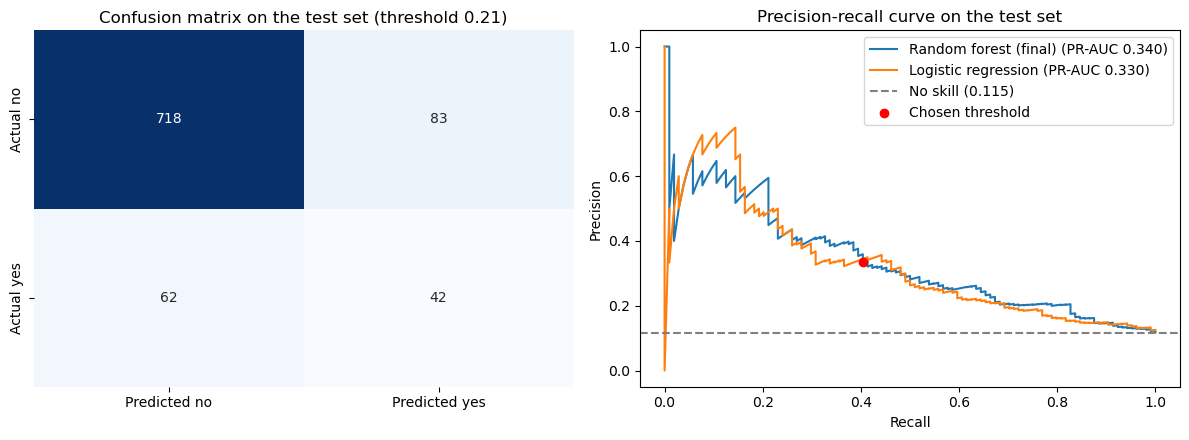

In [15]:
from sklearn.metrics import roc_auc_score, confusion_matrix

proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= best_threshold).astype(int)
proba_train = final_model.predict_proba(X_train)[:, 1]
pred_train = (proba_train >= best_threshold).astype(int)
pred_oof = (oof_final >= best_threshold).astype(int)

# Reference only: tuned logistic regression
lr_ref = clone(tuned["Logistic regression"].best_estimator_).fit(X_train, y_train)
proba_lr = lr_ref.predict_proba(X_test)[:, 1]

print("Test 'yes' rate (PR-AUC of a no-skill model): {:.3f}".format(y_test.mean()))
print("Threshold used: {:.2f} (chosen on the training set)\n".format(best_threshold))

def scores(y_true, proba, pred):
    return [roc_auc_score(y_true, proba), average_precision_score(y_true, proba),
            precision_score(y_true, pred), recall_score(y_true, pred), f1_score(y_true, pred)]

table = pd.DataFrame({
    "Train (in-sample)": scores(y_train, proba_train, pred_train),
    "CV (out-of-fold)": scores(y_train, oof_final, pred_oof),
    "Test": scores(y_test, proba_test, pred_test),
}, index=["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"]).round(3)
print(table.to_string())

print("\nLogistic regression on the test set (context only): ROC-AUC {:.3f} | PR-AUC {:.3f}".format(
    roc_auc_score(y_test, proba_lr), average_precision_score(y_test, proba_lr)))

cm = confusion_matrix(y_test, pred_test)
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Predicted no", "Predicted yes"], yticklabels=["Actual no", "Actual yes"])
axes[0].set_title("Confusion matrix on the test set (threshold {:.2f})".format(best_threshold))

for label, proba in [("Random forest (final)", proba_test), ("Logistic regression", proba_lr)]:
    p_, r_, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(r_, p_, label="{} (PR-AUC {:.3f})".format(label, average_precision_score(y_test, proba)))
axes[1].axhline(y_test.mean(), color="grey", linestyle="--", label="No skill ({:.3f})".format(y_test.mean()))
axes[1].scatter([recall_score(y_test, pred_test)], [precision_score(y_test, pred_test)],
                color="red", zorder=5, label="Chosen threshold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve on the test set")
axes[1].legend()
plt.tight_layout()
plt.show()

**Findings (test set):**

| Metric | Train (in-sample) | CV (out-of-fold) | Test |
|---|---|---|---|
| ROC-AUC | 0.955 | 0.750 | 0.752 |
| PR-AUC | 0.776 | 0.370 | 0.340 |
| Precision | 0.672 | 0.411 | 0.336 |
| Recall | 0.698 | 0.436 | 0.404 |
| F1 | 0.685 | 0.423 | 0.367 |

- **Confusion matrix:** of 905 test clients, the model flags 125 (13.8%). 42 of them subscribe (true positives) and 83 do not (false positives). It misses 62 of the 104 subscribers (false negatives) and correctly leaves 718 non-subscribers alone.
- **Business reading:** among flagged clients 33.6% subscribe, which is **2.9 times the base rate** (11.5%). A call list built this way is much better than random, but about two in three calls still go to clients who will not subscribe, and 60% of subscribers are never called.
- **Generalization:** the test ROC-AUC (0.752) matches cross-validation (0.750). The test PR-AUC (0.340) is 0.030 lower than the cross-validation value (0.370), which is within one fold standard deviation (0.048). The test set has only 104 subscribers, so a drop of this size is within normal sampling noise. Overall the cross-validation estimate was **honest, with a small optimistic bias** (the hyperparameters and the threshold were chosen on it).
- **Recall and F1 are lower on test** (0.404 and 0.367 against 0.436 and 0.423). The threshold was tuned to the training probabilities, and a small change in the number of caught subscribers (a few clients) moves F1 visibly.
- **Is the forest really better than the logistic regression?** On the test set the gap is small: PR-AUC 0.340 against 0.330 (+0.010) and ROC-AUC 0.752 against 0.736. The two precision-recall curves in the plot cross several times and are almost on top of each other for recall above 0.4. The advantage seen in cross-validation (+0.022) is not clearly confirmed on the test set. The honest conclusion is that the forest is **at best slightly better**.
- **Bias vs variance diagnosis:**
  - The forest has a **large variance problem**: ROC-AUC 0.955 on the training data against 0.75 on new data, and PR-AUC 0.776 against 0.34.
  - But variance is not the only limit. The simple logistic regression (small train-validation gap, so low variance) reaches almost the same test score (0.736 ROC-AUC). Regularizing the forest more (Part 3) did not raise the validation score either. If less overfitting does not help and a more flexible model does not help, the ceiling is set by **the information in the 14 features** (and label noise), not by the model type. Better results would need new information, for example the call duration (not allowed), client history or economic indicators.

### 4.2 Error analysis

The aim is to understand **which clients the model gets wrong and why**, not only how many. The analysis uses the **out of fold predictions on the training set** (3,616 clients, 417 subscribers), which is a larger sample than the test set and does not use the test set for further decisions.

Out-of-fold outcome counts at threshold 0.21:
{'TN': 2938, 'FP': 261, 'FN': 235, 'TP': 182}

--- by poutcome ---
             n  yes rate %  flagged %  recall  precision
poutcome                                                
unknown   2947         9.1        6.8    0.28       0.37
failure    404        12.9       20.0    0.44       0.28
other      166        19.3       38.0    0.62       0.32
success     99        65.7      100.0    1.00       0.66

--- by contact ---
              n  yes rate %  flagged %  recall  precision
contact                                                  
cellular   2336        14.3       15.9    0.47       0.42
unknown    1050         4.7        1.4    0.06       0.20
telephone   230        15.2       24.3    0.66       0.41

--- by age group ---
              n  yes rate %  flagged %  recall  precision
age group                                                
31-40      1447         9.7        8.6    0.33       0.38
41-50       937        10.2        7.8 

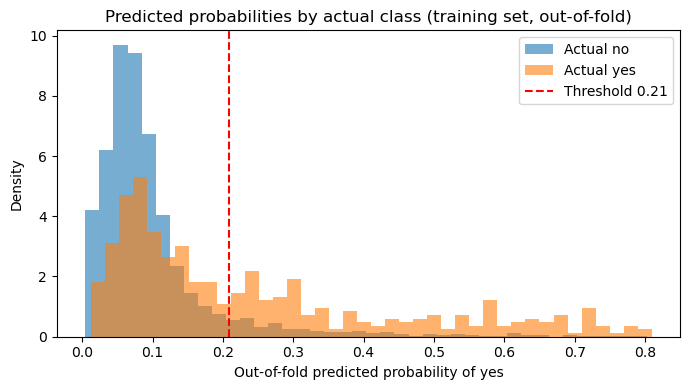

In [16]:
err = X_train.copy()
err["y"] = y_train
err["proba"] = oof_final
err["pred"] = pred_oof
err["outcome"] = np.select(
    [(err.y == 1) & (err.pred == 1), (err.y == 0) & (err.pred == 1), (err.y == 1) & (err.pred == 0)],
    ["TP", "FP", "FN"], default="TN")

print("Out-of-fold outcome counts at threshold {:.2f}:".format(best_threshold))
print(err["outcome"].value_counts().to_dict())

def segment_table(col):
    g = err.groupby(col)
    out = pd.DataFrame({
        "n": g.size(),
        "yes rate %": (g["y"].mean() * 100).round(1),
        "flagged %": (g["pred"].mean() * 100).round(1),
        "recall": g.apply(lambda d: d.loc[d.y == 1, "pred"].mean()).round(2),
        "precision": g.apply(lambda d: d.loc[d.pred == 1, "y"].mean() if d.pred.sum() > 0 else np.nan).round(2),
    })
    return out.sort_values("n", ascending=False)

err["age group"] = pd.cut(err["age"], [0, 30, 40, 50, 60, 100],
                          labels=["<=30", "31-40", "41-50", "51-60", ">60"])

for col in ["poutcome", "contact", "age group"]:
    print("\n--- by", col, "---")
    print(segment_table(col).to_string())

print("\n--- by month (largest 6 months) ---")
print(segment_table("month").head(6).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(err.loc[err.y == 0, "proba"], bins=40, alpha=0.6, label="Actual no", density=True)
ax.hist(err.loc[err.y == 1, "proba"], bins=40, alpha=0.6, label="Actual yes", density=True)
ax.axvline(best_threshold, color="red", linestyle="--", label="Threshold {:.2f}".format(best_threshold))
ax.set_xlabel("Out-of-fold predicted probability of yes")
ax.set_ylabel("Density")
ax.set_title("Predicted probabilities by actual class (training set, out-of-fold)")
ax.legend()
plt.tight_layout()
plt.show()

**Findings (error analysis, out-of-fold predictions at threshold 0.21):**
- The model makes 261 false positives and 235 false negatives, and finds 182 of the 417 subscribers.

**Where the missed subscribers are (false negatives):**
- **Clients never contacted before (`poutcome = unknown`).** This group is 2,947 clients (82% of the data) with a 9.1% subscription rate, so it holds about 270 of the 417 subscribers (about 64%). The recall there is only 0.28, so about **190 of the 235 missed subscribers (about 80%) come from this group**. For these clients the model has little to work with: no result from an earlier campaign, so it relies on weak features such as job, month and housing loan.
- **`contact = unknown`.** 1,050 clients with a 4.7% rate, recall 0.06. The model flags only 1.4% of them and catches about 3 of roughly 50 subscribers. The model is right that this group subscribes less often than average, but it cannot tell the few subscribers apart.
- **May and July.** These are the busiest months and have low subscription rates (6.7% and 9.1%). The recall is 0.16 and 0.19, so the two months together hold roughly 100 of the 235 missed subscribers. Because the base rate is low, the predicted probability rarely reaches 0.21, even for clients who do subscribe.

**Where the model does well:**
- **Previous campaign success.** The 99 clients with `poutcome = success` have a 65.7% rate, and all are flagged (recall 1.00, precision 0.66). This is the cleanest group, but it holds only about 65 subscribers (16% of the total).
- **Cellular and telephone contact** have higher recall (0.47 and 0.66) and a precision of about 0.4.

**Where the model may be biased or unfair:**
- **Clients over 60** (94 clients, 38.3% rate): 88% of them are flagged and the precision is 0.39, which is about the same as the group's base rate. The model flags nearly everyone in this group instead of ranking within it. It uses age as a blanket rule here. If this list were used in practice, it would send most calls to older clients, which can be a problem for vulnerable customers. With only 94 clients, the estimate is also unstable.
- **Middle aged clients (31 to 50)** are the largest groups and have the lowest recall (0.33 to 0.38). The model is least useful for the bulk of the client base.

**What the probability chart shows:**
- The probabilities of actual "yes" and "no" clients **overlap strongly** below about 0.15. Most subscribers have a predicted probability of 0.05 to 0.12, the same range as most non subscribers. For these clients, no threshold can help: they look like typical non subscribers in the 14 features.
- Above about 0.3 the "yes" bars clearly dominate, which is why precision rises at high thresholds (0.55 at 0.4, 0.62 at 0.5).
- **Conclusion:** the subscribers fall into two types. One type is **identifiable** (previous success, older age, cellular contact, certain months) and the model finds them. The other type, which is the majority, is **indistinguishable** from non subscribers using the available features. This is a limit of the information in the data (no call content, no client history, no economic indicators), and tuning the model further is unlikely to change it. This supports the conclusion from 4.1.

### 4.3 Robustness: repeated cross-validation and bootstrap

The scores so far come from one particular split into 5 folds, and the test set has only 104 subscribers. Two checks show how much the conclusions depend on luck:

1. **Repeated cross-validation:** 5-fold cross-validation is repeated 5 times with different random splits, which gives 25 validation scores per model. If the model ranking stays the same across most splits, it is stable.
2. **Bootstrap on the test set:** the 905 test clients are resampled with replacement 1,000 times, and the PR-AUC and ROC-AUC are recomputed each time. The 2.5th and 97.5th percentiles give a **95% interval** that shows how uncertain the test score is. The forest and the logistic regression are compared on the same resamples.

In [17]:
from sklearn.model_selection import RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7)

rep = {}
for name, search in tuned.items():
    rep[name] = cross_validate(clone(search.best_estimator_), X_train, y_train, cv=rcv, n_jobs=-1,
                               scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"})

print("Repeated 5-fold CV (5 repeats = 25 validation scores per model):")
rows = []
for name, r in rep.items():
    rows.append({"model": name,
                 "ROC-AUC mean": round(r["test_roc_auc"].mean(), 3),
                 "ROC-AUC std": round(r["test_roc_auc"].std(), 3),
                 "PR-AUC mean": round(r["test_pr_auc"].mean(), 3),
                 "PR-AUC std": round(r["test_pr_auc"].std(), 3),
                 "PR-AUC min": round(r["test_pr_auc"].min(), 3),
                 "PR-AUC max": round(r["test_pr_auc"].max(), 3)})
print(pd.DataFrame(rows).set_index("model").to_string())

for name in rep:
    if name != "Logistic regression":
        d = rep[name]["test_pr_auc"] - rep["Logistic regression"]["test_pr_auc"]
        print("{:18s} - Logistic regression: mean {:+.3f} | better in {}/25 splits".format(
            name, d.mean(), int((d > 0).sum())))

# Bootstrap on the test set
rng = np.random.RandomState(0)
y_arr = y_test.values
boot = {"RF PR-AUC": [], "LR PR-AUC": [], "RF ROC-AUC": [], "RF minus LR PR-AUC": []}
for _ in range(1000):
    idx = rng.randint(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() == 0:
        continue
    a = average_precision_score(y_arr[idx], proba_test[idx])
    b = average_precision_score(y_arr[idx], proba_lr[idx])
    boot["RF PR-AUC"].append(a)
    boot["LR PR-AUC"].append(b)
    boot["RF ROC-AUC"].append(roc_auc_score(y_arr[idx], proba_test[idx]))
    boot["RF minus LR PR-AUC"].append(a - b)

print("\nBootstrap (1000 resamples of the test set), 95% intervals:")
for k, v in boot.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    print("{:20s} {:.3f} to {:.3f}".format(k, lo, hi))
print("Share of resamples where the forest beats the logistic regression: {:.0%}".format(
    np.mean(np.array(boot["RF minus LR PR-AUC"]) > 0)))

Repeated 5-fold CV (5 repeats = 25 validation scores per model):
                     ROC-AUC mean  ROC-AUC std  PR-AUC mean  PR-AUC std  PR-AUC min  PR-AUC max
model                                                                                          
Logistic regression         0.720        0.033        0.357       0.047       0.283       0.477
Random forest               0.745        0.030        0.386       0.045       0.309       0.476
Gradient boosting           0.738        0.028        0.377       0.043       0.314       0.482
Random forest      - Logistic regression: mean +0.028 | better in 19/25 splits
Gradient boosting  - Logistic regression: mean +0.020 | better in 19/25 splits

Bootstrap (1000 resamples of the test set), 95% intervals:
RF PR-AUC            0.262 to 0.436
LR PR-AUC            0.254 to 0.435
RF ROC-AUC           0.698 to 0.802
RF minus LR PR-AUC   -0.040 to 0.049
Share of resamples where the forest beats the logistic regression: 61%


**Findings (robustness):**

| Model | ROC-AUC (25 splits) | PR-AUC (25 splits) | Beats logistic regression |
|---|---|---|---|
| Logistic regression | 0.720 +/- 0.033 | 0.357 +/- 0.047 | (reference) |
| Random forest | 0.745 +/- 0.030 | 0.386 +/- 0.045 | +0.028, 19 of 25 splits |
| Gradient boosting | 0.738 +/- 0.028 | 0.377 +/- 0.043 | +0.020, 19 of 25 splits |

- **The model ranking is stable under repeated cross-validation.** The order (forest, then boosting, then logistic regression) is the same as in the single 5-fold run in Part 3, and the forest's mean PR-AUC (0.386) is close to the earlier value (0.381). The choice of the final model does not depend on one lucky split.
- **The gap is small compared with the noise.** The forest's advantage over the logistic regression is +0.028 PR-AUC, which is about 0.6 of one standard deviation (0.045). A single split can swing a model's PR-AUC a lot: the forest's 25 scores range from 0.309 to 0.476. "19 of 25" overstates the evidence, because the 25 splits reuse the same 3,616 clients, so the splits are not independent.
- **The test score is consistent with cross-validation.** The test PR-AUC of the forest (0.340) lies inside the 25-split range (0.309 to 0.476), at the lower end. This is the normal size of variation, not a sign of a failed model.
- **The test set cannot separate the models.** The bootstrap 95% interval for the forest's test PR-AUC is **0.262 to 0.436**, and for ROC-AUC 0.698 to 0.802. The interval for the *difference* between the forest and the logistic regression is **−0.040 to +0.049**, which includes zero, and the forest wins in only 61% of resamples. With 104 subscribers in the test set, a +0.01 to +0.03 difference cannot be confirmed.
- **Overall reading:** the evidence that tree models rank clients slightly better than a linear model is consistent in sign (cross-validation, repeated cross-validation, test set) but small. The random forest stays the final model, but the logistic regression is a defensible choice if interpretability or stability matters more than about 0.03 PR-AUC.

### 4.4 Learning curve: would more data help?

A learning curve trains the model on 20% to 100% of the training rows and plots the training and validation PR-AUC. It answers a practical question: **is the model limited by bias or by variance?**
- If the validation score is still rising and a large gap remains, the model is limited by variance, and more data (or more regularization) can help.
- If the validation score is flat while the training score is low or close to it, the model is limited by bias or by the information in the features, and more data of the same kind will not help.

Logistic regression    validation PR-AUC by size: [0.328 0.342 0.355 0.357 0.358]
                       training   PR-AUC by size: [0.499 0.406 0.395 0.404 0.39 ]
Random forest (final)  validation PR-AUC by size: [0.339 0.359 0.367 0.378 0.382]
                       training   PR-AUC by size: [0.914 0.882 0.829 0.804 0.795]
Training sizes: [ 578 1156 1735 2313 2892]


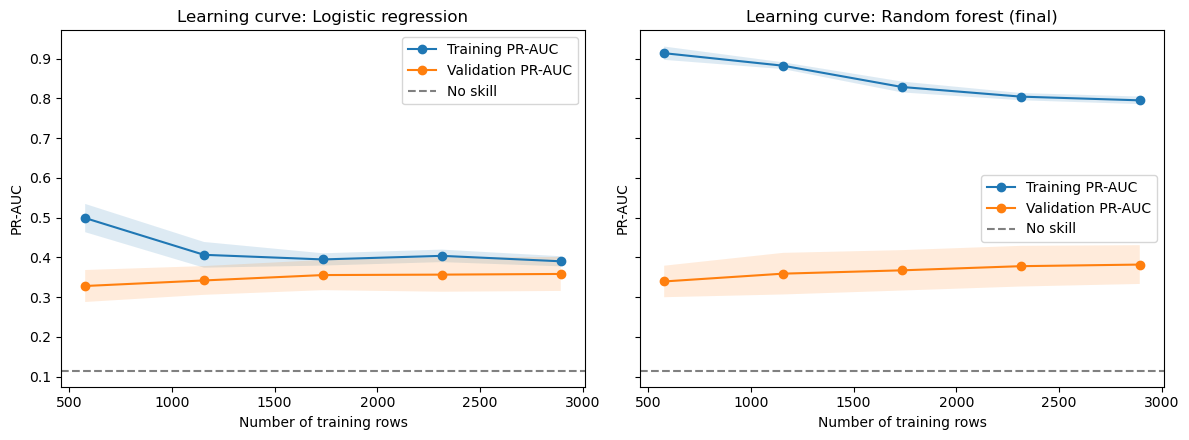

In [18]:
from sklearn.model_selection import learning_curve

sizes = [0.2, 0.4, 0.6, 0.8, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, (name, model) in zip(axes, [("Logistic regression", tuned["Logistic regression"].best_estimator_),
                                    ("Random forest (final)", tuned["Random forest"].best_estimator_)]):
    ts, tr_sc, va_sc = learning_curve(clone(model), X_train, y_train, cv=cv, train_sizes=sizes,
                                      scoring="average_precision", n_jobs=-1)
    ax.plot(ts, tr_sc.mean(axis=1), "o-", label="Training PR-AUC")
    ax.fill_between(ts, tr_sc.mean(axis=1) - tr_sc.std(axis=1), tr_sc.mean(axis=1) + tr_sc.std(axis=1), alpha=0.15)
    ax.plot(ts, va_sc.mean(axis=1), "o-", label="Validation PR-AUC")
    ax.fill_between(ts, va_sc.mean(axis=1) - va_sc.std(axis=1), va_sc.mean(axis=1) + va_sc.std(axis=1), alpha=0.15)
    ax.axhline(y_train.mean(), color="grey", linestyle="--", label="No skill")
    ax.set_title("Learning curve: " + name)
    ax.set_xlabel("Number of training rows")
    ax.set_ylabel("PR-AUC")
    ax.legend()
    print("{:22s} validation PR-AUC by size: {}".format(name, np.round(va_sc.mean(axis=1), 3)))
    print("{:22s} training   PR-AUC by size: {}".format("", np.round(tr_sc.mean(axis=1), 3)))

print("Training sizes:", ts)
plt.tight_layout()
plt.show()

**Findings (learning curves):**

| Training rows | Logistic regression (val / train) | Random forest (val / train) |
|---|---|---|
| 578 | 0.328 / 0.499 | 0.339 / 0.914 |
| 1,156 | 0.342 / 0.406 | 0.359 / 0.882 |
| 1,735 | 0.355 / 0.395 | 0.367 / 0.829 |
| 2,313 | 0.357 / 0.404 | 0.378 / 0.804 |
| 2,892 | 0.358 / 0.390 | 0.382 / 0.795 |

- **Logistic regression: bias-limited.** The training and validation curves almost meet (0.390 vs 0.358), and the validation curve is flat after about 1,700 rows (0.355 to 0.358). More data of the same kind would not improve it. Its limit is the straight-line form of the model and the information in the features.
- **Random forest: variance-limited, but with a ceiling.** The training score stays far above validation (0.795 vs 0.382) at every size. The gap shrinks as data grows (0.575 at 578 rows, 0.413 at 2,892 rows) and the validation curve is still creeping up (0.378 to 0.382 over the last step), so more data would help the forest a little. The curve is flattening, though, so a large gain is unlikely: the last 20% of data added about +0.004.
- **Both models approach about 0.36 to 0.39 PR-AUC.** This is the information ceiling already seen in the error analysis (4.2). The last 20% of the data added only +0.004, so doubling the data would probably add about 0.01 to 0.02 PR-AUC (an extrapolation, not a measurement), not a different level of performance.
- **Bias-variance summary for Part 4:** logistic regression = high bias, low variance. Random forest = low bias, high variance. The random forest wins by a small margin because its variance costs less than the non-linear effects it captures are worth.

### 4.5 Calibration and feature importance

**Calibration:** if the model says "30%", do about 30% of those clients subscribe? This matters because the bank may use the score to plan calls. The check compares the average predicted probability with the real subscription rate inside 8 groups of clients ordered by score, plus the Brier score (lower is better; a model that always predicts the base rate sets the reference).

**Feature importance:** permutation importance shuffles one feature at a time on the test set and measures how much the PR-AUC drops. A big drop means the model relies on that feature. A drop near zero or below zero means the feature adds nothing (or only noise). It is computed on the raw features, so each of the 14 columns gets one value.

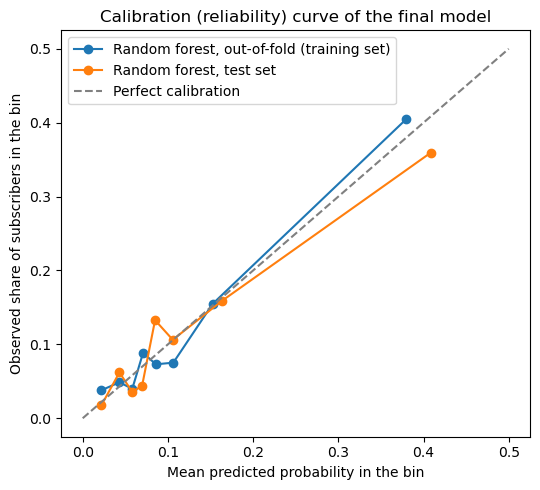

Mean predicted vs actual 'yes' rate (out-of-fold): 0.115 vs 0.115
Mean predicted vs actual 'yes' rate (test)       : 0.120 vs 0.115
Brier score, random forest (test)        : 0.090
Brier score, logistic regression (test)  : 0.091
Brier score, always predict the base rate: 0.102


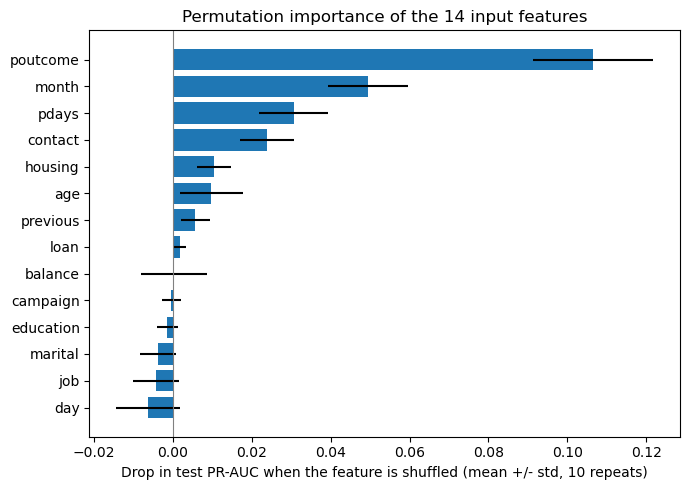

  feature  importance    std
 poutcome      0.1066 0.0152
    month      0.0495 0.0102
    pdays      0.0306 0.0088
  contact      0.0238 0.0068
  housing      0.0105 0.0043
      age      0.0097 0.0080
 previous      0.0056 0.0037
     loan      0.0017 0.0015
  balance      0.0002 0.0084
 campaign     -0.0004 0.0023
education     -0.0014 0.0027
  marital     -0.0038 0.0045
      job     -0.0042 0.0058
      day     -0.0064 0.0080


In [19]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.inspection import permutation_importance

# 1) Calibration
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, proba, y_true in [("Random forest, out-of-fold (training set)", oof_final, y_train),
                             ("Random forest, test set", proba_test, y_test)]:
    frac, mean_pred = calibration_curve(y_true, proba, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", label=label)
ax.plot([0, 0.5], [0, 0.5], "--", color="grey", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability in the bin")
ax.set_ylabel("Observed share of subscribers in the bin")
ax.set_title("Calibration (reliability) curve of the final model")
ax.legend()
plt.tight_layout()
plt.show()

print("Mean predicted vs actual 'yes' rate (out-of-fold): {:.3f} vs {:.3f}".format(oof_final.mean(), y_train.mean()))
print("Mean predicted vs actual 'yes' rate (test)       : {:.3f} vs {:.3f}".format(proba_test.mean(), y_test.mean()))
print("Brier score, random forest (test)        : {:.3f}".format(brier_score_loss(y_test, proba_test)))
print("Brier score, logistic regression (test)  : {:.3f}".format(brier_score_loss(y_test, proba_lr)))
print("Brier score, always predict the base rate: {:.3f}".format(
    brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))))

# 2) Permutation importance on the test set
pi = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                            n_repeats=10, random_state=0, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean, "std": pi.importances_std})
imp = imp.sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp["feature"], imp["importance"], xerr=imp["std"])
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Drop in test PR-AUC when the feature is shuffled (mean +/- std, 10 repeats)")
ax.set_title("Permutation importance of the 14 input features")
plt.tight_layout()
plt.show()

print(imp.sort_values("importance", ascending=False).round(4).to_string(index=False))

**Findings:**
- **Calibration is good.** The average predicted probability matches the real rate (0.115 vs 0.115 out-of-fold, 0.120 vs 0.115 on the test set), and the points of the reliability curve stay close to the diagonal. The highest-score group is predicted at about 0.38 and observed at about 0.41. The lower groups wobble by up to 0.03, which is expected with so few subscribers per group.
- The forest's Brier score on the test set (0.090) is below the constant base-rate prediction (0.102), but only by about 12%. It is almost the same as the logistic regression (0.091). So the scores can be read as approximate probabilities, unlike the class-weight and SMOTE models of Part 2 (Brier about 0.19), but they carry limited extra information.
- **Feature importance:** `poutcome` is by far the most important feature (PR-AUC drop of 0.107), followed by `month` (0.050), `pdays` (0.031) and `contact` (0.024). `housing`, `age` and `previous` follow with 0.006 to 0.011. This matches the EDA of Milestone 3 and the error analysis in 4.2.
- `job`, `marital`, `education`, `day`, `balance` and `campaign` are at or below zero. Shuffling them does not hurt the model, so they are mostly noise for this forest. The importances come from only 104 test subscribers, so only the first four features are clearly above the noise (std 0.007 to 0.015).
- Consequence: a smaller model with fewer features could perform about as well and would be easier to explain and maintain. Feature selection is listed as a future improvement.
- **Caveat:** `poutcome`, `pdays` and `previous` describe the same earlier campaign (`pdays = -1` exactly when `poutcome = unknown`), so when one is shuffled the others partly cover for it. Their individual importances are probably underestimated, and their combined importance is larger than any single value shows. The importance was computed on the test set for reporting only, and no decision was changed because of it.

### 4.6 Augmentation re-tested on the final model (before vs after)

In Part 2 augmentation was tested on a logistic regression. A flexible model such as the random forest can react differently, for example by memorizing synthetic points. So the same comparison is repeated for the final forest, with the same preprocessing, the same folds and the same settings.

In [20]:
rf_params = dict(n_estimators=300, random_state=42, n_jobs=-1,
                 max_depth=12, min_samples_leaf=3, max_features=0.3)

rf_variants = {
    "Random forest (final)": make_pipe(RandomForestClassifier(**rf_params)),
    "RF + class weights": make_pipe(RandomForestClassifier(class_weight="balanced_subsample", **rf_params)),
    "RF + SMOTE": make_pipe(RandomForestClassifier(**rf_params), use_smote=True),
}

scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}
fold_pr = {}
for name, pipe in rf_variants.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    fold_pr[name] = r["test_pr_auc"]
    print("{:24s} ROC-AUC {:.3f} +/- {:.3f} | PR-AUC {:.3f} +/- {:.3f}".format(
        name, r["test_roc_auc"].mean(), r["test_roc_auc"].std(),
        r["test_pr_auc"].mean(), r["test_pr_auc"].std()))

for name in list(rf_variants)[1:]:
    d = fold_pr[name] - fold_pr["Random forest (final)"]
    print("{:24s} PR-AUC difference vs final: mean {:+.3f} | better in {}/5 folds".format(
        name, d.mean(), int((d > 0).sum())))

Random forest (final)    ROC-AUC 0.751 +/- 0.033 | PR-AUC 0.381 +/- 0.048
RF + class weights       ROC-AUC 0.736 +/- 0.034 | PR-AUC 0.360 +/- 0.053
RF + SMOTE               ROC-AUC 0.738 +/- 0.031 | PR-AUC 0.364 +/- 0.052
RF + class weights       PR-AUC difference vs final: mean -0.020 | better in 0/5 folds
RF + SMOTE               PR-AUC difference vs final: mean -0.016 | better in 0/5 folds


**Findings:**

| Random forest version | ROC-AUC | PR-AUC | PR-AUC change vs final | Better than final in |
|---|---|---|---|---|
| Final (no augmentation) | 0.751 | 0.381 | (reference) | (reference) |
| + class weights | 0.736 | 0.360 | −0.020 | 0 of 5 folds |
| + SMOTE | 0.738 | 0.364 | −0.016 | 0 of 5 folds |

- **Augmentation made the final model worse.** Both class weights and SMOTE lower ROC-AUC (by 0.013 to 0.015) and PR-AUC (by 0.016 to 0.020), and neither beats the plain forest in any of the 5 folds. With the logistic regression in Part 2 the differences were small and mixed (class weights −0.003, better in 3 of 5 folds). The loss is larger for the flexible model, especially for class weights (−0.020 vs −0.003).
- Each loss is less than half of one fold standard deviation (0.048), but it has the same sign in every fold. Five folds are a small sample, so this is consistent evidence of a small loss, not proof.
- **One possible reason (not tested here):** the forest can already carve out the "yes" region with its trees and a low threshold, so extra weight or synthetic points mainly add noise to the many small leaves (`min_samples_leaf = 3`), where it is already most prone to overfit.
- **Conclusion:** the finding of Part 2 holds for both the simple and the final model. The imbalance is better handled by moving the decision threshold than by augmentation.

**Conclusion of Part 4:** the final random forest generalizes as expected from cross-validation (test ROC-AUC 0.752, PR-AUC 0.340 with a wide 95% interval of 0.26 to 0.44). It lifts the hit rate of a call list from 11.5% to 33.6% (about 2.9 times) while finding 40% of subscribers. Its probabilities are close to the real rates (4.5), and its predictions rely mainly on `poutcome`, `month`, `pdays` and `contact`. Augmentation lowered its PR-AUC (4.6). The errors are concentrated in clients who were never contacted before and in low-rate months. The advantage over a simple logistic regression is small and cannot be confirmed on the test set alone.

## Part 5: Analytical Reflection

**Does the model generalize?** Yes, within limits. The test ROC-AUC (0.752) matches cross-validation (0.750), and the test PR-AUC (0.340) lies inside the range of 25 repeated-CV scores (0.309 to 0.476). The call list lifts the hit rate from 11.5% to 33.6% (2.9 times) at recall 0.40. But the forest is heavily overfit (training ROC-AUC 0.955 vs 0.752 on test), and with 104 test subscribers the 95% bootstrap interval for PR-AUC is wide (0.262 to 0.436). Its edge over the logistic regression (+0.028 in repeated CV, +0.010 on test; difference interval −0.040 to +0.049) is consistent in sign but not confirmed. I treat it as "modestly better", not proven.

**Structural weaknesses**
- **Information ceiling.** The logistic regression is bias-limited and the forest gains little from more data. 64% of subscribers were never contacted before, where the features carry little signal, and 83% of the missed subscribers come from this group.
- **Excluded information.** `duration` (r = 0.40) is not known before a call and was removed to prevent leakage. This lowers the score but keeps the model usable before a call.
- **Threshold choice.** The threshold (0.21) maximizes F1, which weighs precision and recall equally, and it was tuned on the same out-of-fold predictions that are reported, so the CV figures are slightly optimistic.
- **No time information.** `month` has no year, so time-based validation was not possible.

**Deployment risks**
- **Drift.** The data covers one campaign period, and `month` and `poutcome` are among the strongest features. Calibration is good now (4.5) but must be monitored.
- **Fairness.** 88% of clients over 60 are flagged, with precision (0.39) equal to that group's base rate (38%). A list based on this model would send most calls to older clients, a risk for vulnerable customers and for compliance.
- **Feedback loop.** The model learns only from contacted clients. If it decides who is called, future data will be biased towards the clients it already prefers.
- **Rare categories** (for example 38 "unknown" jobs) give unstable predictions.

**Was augmentation beneficial?** No. On the logistic regression, class weights and SMOTE raised recall at 0.5 from 0.15 to about 0.57, but PR-AUC did not improve (−0.003 and −0.012), the baseline with a tuned threshold beat both (F1 0.392 vs 0.377 and 0.368), and the probabilities were distorted (mean 0.116 to about 0.41; Brier 0.089 to about 0.19). On the final forest, both lowered PR-AUC (0.381 to 0.360 and 0.364) in all 5 folds. Moving the threshold was the better fix, so SMOTE was left out.

**Future improvements**
1. **Cost-based threshold:** expected profit per call (value of a deposit x precision - cost of a call).
2. **Time-aware validation** with contact dates, to measure drift directly.
3. **Richer features** for the never-contacted group: client history, campaign timing, macroeconomic indicators.
4. **Two-stage scoring:** the pre-call model selects who to call, and a second model adds `duration` during the call.
5. **Uplift modeling:** predict who is persuaded by a call, not who would subscribe anyway.
6. **SHAP explanations,** fairness checks by age group, and drift monitoring (for example the population stability index).
7. **Nested cross-validation and more subscribers,** so differences of 0.02 to 0.03 PR-AUC can be tested.